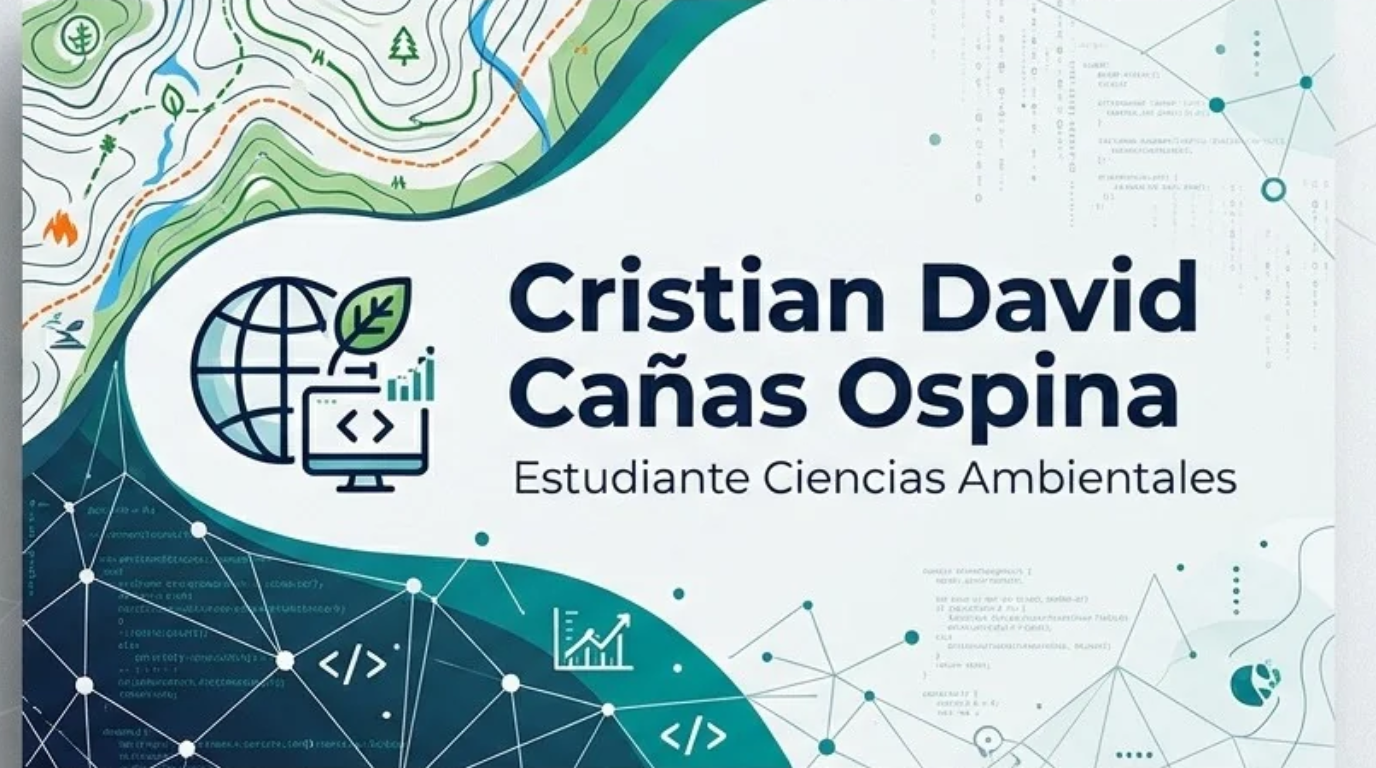

<sub>Imagen generada con Ai</sub>

![](/img/presentacion_EDA.jpg) 

---
# Análisis Exploratorio de Datos (EDA)

## Evidencia AA3-EV02:

**Curso:** Análisis Exploratorio de Datos en Python

**Proyecto:** Datos sector inmobiliario

---
---
Autor: Cristian David Cañas Ospina
[GitHub](https://github.com/cd7-gis)

---
---



---
---
# Planteamiento del problema
---

El mercado de bienes raíces en el país presenta una alta dispersión en los precios, las áreas de terreno y las construcciones, abarcando desde pequeños locales comerciales hasta grandes macro-proyectos y lotes rurales.

Esta heterogeneidad dificulta la tasación y el análisis de inversión si no se estudian detalladamente.

Por ello, es necesario analizar cómo las características físicas, la ubicación y la tipología del inmueble se relacionan con el precio.

---
---

---
---
# Pregunta
---

¿Cómo se relacionan el área construida, el área del terreno y el tipo de inmueble con los precios registrados?

---
---


---
---
# 1. Importación librerias y exploración de datos
---
Se importó el archivo en formato CSV utilizando la biblioteca pandas, especificando la ruta local del archivo de trabajo.

---
---

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [9]:

ruta = ("C:\Programacion\eda\data\Data_Caso_Propuesto.csv")
df = pd.read_csv(ruta)


In [10]:
df

,Codigo,Ciudad,Departamento,Barrio,Direccion,Area Terreno,Area Construida,Detalle Disponibilidad,Estrato,Precio,Tipo de Inmueble,Datos Adicionales
0,17180,BOGOTA,CUNDINAMARCA,NaN,AV CR 7 NO. 166 - 51 LT B,0.00,0.0,COMERCIALIZABLE CON RESTRICCION,TRES,2.958081e+10,LOTE COMERCIAL,ESTE INMUEBLE SE COMERCIALIZARÁ A TRAVES DE SU...
1,19292,BOGOTA,CUNDINAMARCA,NaN,CL 72 No. 12 - 77,0.00,0.0,COMERCIALIZABLE,COMERCIAL,1.646059e+10,EDIFICIO,NaN
2,19292,BOGOTA,CUNDINAMARCA,NaN,CL 72 No. 12 - 77,0.00,0.0,COMERCIALIZABLE VENTA ANTICIPADA,COMERCIAL,1.646059e+10,EDIFICIO,NaN
3,2575,SOGAMOSO,BOYACÁ,CENTRO,CRA. 10 #11- 78/80 Ó CL 12 # 9 - 77/85 Ó CALLE...,1655.08,7269.0,COMERCIALIZABLE CON RESTRICCION,CUATRO,1.376828e+10,CLINICA,ESTE INMUEBLE SE COMERCIALIZARÁ A TRAVÉS DE SU...
4,11409,BUGA,VALLE DEL CAUCA,VEREDA CHAMBIMBAL,LT A1-A24 B1-B79 C1-C51 D1-D9 STA ROSA LT1-46 ...,3217197.00,22724.0,COMERCIALIZABLE FIDUCIA,RURAL,4.523379e+10,LOTE MIXTO,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...
458,12709,CALI,VALLE DEL CAUCA,PRADOS DEL NORTE,CL 30N # 2B-38 LOCAL 562 CENTRO COMERCIAL SA...,0.00,0.0,COMERCIALIZABLE CON RESTRICCION,CUATRO,2.960534e+07,LOCAL,¡OPORTUNIDAD PARA INVERTIR! LOCAL EN PROINDIVI...
459,17992,BOGOTA,CUNDINAMARCA,NaN,CR 70 NO. 49-77,0.00,0.0,COMERCIALIZABLE CON RESTRICCION,CUATRO,1.448242e+09,CASA,NaN
460,12708,CALI,VALLE DEL CAUCA,PRADOS DEL NORTE,CL 30N # 2B-38 LOCAL 564 CENTRO COMERCIAL SAN...,0.00,0.0,COMERCIALIZABLE CON RESTRICCION,CUATRO,2.070134e+07,LOCAL,¡OPORTUNIDAD PARA INVERTIR! LOCAL EN PROINDIVI...
461,12706,CALI,VALLE DEL CAUCA,PRADOS DEL NORTE,CL 30N # 2B-38 LOCAL 367 CENTRO COMERCIAL SAN...,0.00,0.0,COMERCIALIZABLE CON RESTRICCION,CUATRO,2.060800e+07,LOCAL,¡OPORTUNIDAD PARA INVERTIR! LOCAL EN PROINDIVI...


---
---
# Total registros
---

- Columnas: 12
- Filas: 463

---

### Columnas

- **Código:** Númerica
- **Ciudad:** Categórica
- **Departamento:** Categórica
- **Barrio:** Categórica
- **Dirección:** Categórica
- **Área Terreno:** Númerica
- **Área Construida:** Númerica
- **Detalle Disponibilidad:** Categórica
- **Estrato:** Categórica
- **Precio:** Númerica
- **Tipo de Inmueble:** Categórica
- **Datos Adicionales:** Categórica

---
---

In [11]:
df.isnull().sum()

Codigo                      0
Ciudad                      0
Departamento                0
Barrio                    423
Direccion                   0
Area Terreno                0
Area Construida             0
Detalle Disponibilidad      0
Estrato                     0
Precio                      0
Tipo de Inmueble            0
Datos Adicionales         345
dtype: int64

In [12]:
df['Barrio'] = df['Barrio'].fillna('NO ESPECIFICADO')
df['Datos Adicionales'] = df['Datos Adicionales'].fillna('SIN DATOS')


In [13]:

df = df.drop_duplicates()

---
---
# 2. Limpieza, validación de datos
---

Al evaluar los nulos con

```
df.isnull().sum()
```
Se encontró que para Barrio hay 423 valores nulos y para Datos Adicionales hay 345 valores nulos, no se encuentran registros duplicados.

No se eliminaron los registros con valores nulos porque representaban una proporción muy alta del dataset:


En lugar de solo eliminar los valor nulos, el dataset se habría reducido a solo 23 filas, perdiendo información valiosa sobre precios, áreas y tipos de inmueble, así que se procedio a rellenar los valores con "NO ESPECIFICADO" para Barrio y "SIN DATOS" para Datos Adicionales y así conservar a todos los datos.

---
---

In [14]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 463 entries, 0 to 462
Data columns (total 12 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Codigo                  463 non-null    int64  
 1   Ciudad                  463 non-null    object 
 2   Departamento            463 non-null    object 
 3   Barrio                  463 non-null    object 
 4   Direccion               463 non-null    object 
 5   Area Terreno            463 non-null    float64
 6   Area Construida         463 non-null    float64
 7   Detalle Disponibilidad  463 non-null    object 
 8   Estrato                 463 non-null    object 
 9   Precio                  463 non-null    float64
 10  Tipo de Inmueble        463 non-null    object 
 11  Datos Adicionales       463 non-null    object 
dtypes: float64(3), int64(1), object(8)
memory usage: 43.5+ KB


In [15]:
print(df.describe())

             Codigo  Area Terreno  Area Construida        Precio
count    463.000000  4.630000e+02       463.000000  4.630000e+02
mean   18003.151188  1.515204e+04        87.517279  6.672032e+08
std     1992.191499  1.827101e+05      1137.469077  3.272992e+09
min     2575.000000  0.000000e+00         0.000000  4.650000e+06
25%    18184.500000  0.000000e+00         0.000000  1.230500e+07
50%    18332.000000  0.000000e+00         0.000000  1.587000e+07
75%    18539.500000  0.000000e+00         0.000000  1.379955e+08
max    19344.000000  3.217197e+06     22724.000000  4.523379e+10


In [16]:
variables = ['Precio', 'Area Construida', 'Area Terreno']

for var in variables:
    print(f"--- Estadísticas para: {var} ---")
    print(f"Media: {df[var].mean():}")
    print(f"Mediana: {df[var].median():,.2f}")
    print(f"Desviación Estándar: {df[var].std():,.2f}")
    print(f"Mínimo: {df[var].min():,.2f}")
    print(f"Máximo: {df[var].max():,.2f}")


    cv = (df[var].std() / df[var].mean()) * 100
    print(f"Coeficiente de Variación: {cv:.2f}%\n")

--- Estadísticas para: Precio ---
Media: 667203190.312095
Mediana: 15,870,000.00
Desviación Estándar: 3,272,992,027.69
Mínimo: 4,650,000.00
Máximo: 45,233,789,820.00
Coeficiente de Variación: 490.55%

--- Estadísticas para: Area Construida ---
Media: 87.51727861771059
Mediana: 0.00
Desviación Estándar: 1,137.47
Mínimo: 0.00
Máximo: 22,724.00
Coeficiente de Variación: 1299.71%

--- Estadísticas para: Area Terreno ---
Media: 15152.036285097192
Mediana: 0.00
Desviación Estándar: 182,710.10
Mínimo: 0.00
Máximo: 3,217,197.00
Coeficiente de Variación: 1205.85%



---
---
 # Estadística descriptiva
---
<p>
 A partir de los estadísticos calculados en el bloque anterior, se destacan los siguientes comportamientos en el mercado inmobiliario registrado:

 <ul>
  <li> Para <b>Precio:</b> </li>
   <ul>

   <li>Media es de &#36 667 203 190 (COP)</li>
   <li>Mediana es de  &#36 15 870 000 (COP)</li>
   <li>Valor mínimo es de &#36 4 650 000 millones (COP)</li>
   <li>Valor máximo es de &#36 45 233 789 820 (COP)</li>
   <li>Desviación estándar es de &#36 3 272 992 027 (COP)</li>
   <li>Coeficiente de variación es de 490,55% </li>

  </ul>

  <li>Para <b>Área Construida:</b>
   <ul>

   <li>Media es de 87, 52 m<sup>2</sup></li>
   <li>Mediana es de  0 m<sup>2</sup></li>
   <li>Valor mínimo es de 0 m<sup>2</sup></li>
   <li>Valor máximo es de 22 724 m<sup>2</sup></li>
   <li>Desviación estándar es de 1 137 m<sup>2</sup></li>
   <li>Coeficiente de variación es de 1299,71%</li>
   </ul>


  <li>Para <b>Área de Terreno:</b></li>
   <ul>

   <li>Media es de 15 152 m<sup>2</sup></li>
   <li>Mediana es de  0 m<sup>2</sup></li>
   <li>Valor mínimo es de 0 m<sup>2</sup></li>
   <li>Valor máximo es de 3 217 197 m<sup>2</sup></li>
   <li>Desviación estándar es de 182 710 m<sup>2</sup></li>
   <li>Coeficiente de variación es de 1205,85% </li>

  </ul>

 </ul>
</p>

## Análisis
---
Los datos de los **Precios**  evidencian como se agrupan  en valores bajos teniendo en cuenta que la mediana es de 15 870 000 millones de pesos (COP), mientras la media es un valor que corresponde a 667 203 190 millones de pesos, quiere decir que hay unos bienes Inmobiliarios Con valores elevados o valores atípicos que hacen que los valores promedios sean tan altos.

El coeficiente de variación del precio, evidencia una dispersión muy alta, lo que significa que hay precios muy diferentes,pueden explicarse como cada tipo de inmueble, área contruida, el área del terreno, el estrato y la ubicación.  

Al igual que precio para área de terreno también presenta una alta dispersión, la diferencia entre la media y la mediana evidencia como los terrenos de gran extensión dominan sobre el promedio.

Para área del construida al tener una media de 87,52 m<sup>2</sup> y una
mediana de 0 m<sup>2</sup>, sugiere que gran parte de los registros son lotes o no han reportado el área construida.

---
---

In [17]:
df


,Codigo,Ciudad,Departamento,Barrio,Direccion,Area Terreno,Area Construida,Detalle Disponibilidad,Estrato,Precio,Tipo de Inmueble,Datos Adicionales
0,17180,BOGOTA,CUNDINAMARCA,NO ESPECIFICADO,AV CR 7 NO. 166 - 51 LT B,0.00,0.0,COMERCIALIZABLE CON RESTRICCION,TRES,2.958081e+10,LOTE COMERCIAL,ESTE INMUEBLE SE COMERCIALIZARÁ A TRAVES DE SU...
1,19292,BOGOTA,CUNDINAMARCA,NO ESPECIFICADO,CL 72 No. 12 - 77,0.00,0.0,COMERCIALIZABLE,COMERCIAL,1.646059e+10,EDIFICIO,SIN DATOS
2,19292,BOGOTA,CUNDINAMARCA,NO ESPECIFICADO,CL 72 No. 12 - 77,0.00,0.0,COMERCIALIZABLE VENTA ANTICIPADA,COMERCIAL,1.646059e+10,EDIFICIO,SIN DATOS
3,2575,SOGAMOSO,BOYACÁ,CENTRO,CRA. 10 #11- 78/80 Ó CL 12 # 9 - 77/85 Ó CALLE...,1655.08,7269.0,COMERCIALIZABLE CON RESTRICCION,CUATRO,1.376828e+10,CLINICA,ESTE INMUEBLE SE COMERCIALIZARÁ A TRAVÉS DE SU...
4,11409,BUGA,VALLE DEL CAUCA,VEREDA CHAMBIMBAL,LT A1-A24 B1-B79 C1-C51 D1-D9 STA ROSA LT1-46 ...,3217197.00,22724.0,COMERCIALIZABLE FIDUCIA,RURAL,4.523379e+10,LOTE MIXTO,SIN DATOS
...,...,...,...,...,...,...,...,...,...,...,...,...
458,12709,CALI,VALLE DEL CAUCA,PRADOS DEL NORTE,CL 30N # 2B-38 LOCAL 562 CENTRO COMERCIAL SA...,0.00,0.0,COMERCIALIZABLE CON RESTRICCION,CUATRO,2.960534e+07,LOCAL,¡OPORTUNIDAD PARA INVERTIR! LOCAL EN PROINDIVI...
459,17992,BOGOTA,CUNDINAMARCA,NO ESPECIFICADO,CR 70 NO. 49-77,0.00,0.0,COMERCIALIZABLE CON RESTRICCION,CUATRO,1.448242e+09,CASA,SIN DATOS
460,12708,CALI,VALLE DEL CAUCA,PRADOS DEL NORTE,CL 30N # 2B-38 LOCAL 564 CENTRO COMERCIAL SAN...,0.00,0.0,COMERCIALIZABLE CON RESTRICCION,CUATRO,2.070134e+07,LOCAL,¡OPORTUNIDAD PARA INVERTIR! LOCAL EN PROINDIVI...
461,12706,CALI,VALLE DEL CAUCA,PRADOS DEL NORTE,CL 30N # 2B-38 LOCAL 367 CENTRO COMERCIAL SAN...,0.00,0.0,COMERCIALIZABLE CON RESTRICCION,CUATRO,2.060800e+07,LOCAL,¡OPORTUNIDAD PARA INVERTIR! LOCAL EN PROINDIVI...


---
---
# 3. Transformación y visualización
---
Fue necedario dejarlo en escala logarítmica ya que kos números son muy grandes y no se vizualizan en las gráficas

---
---

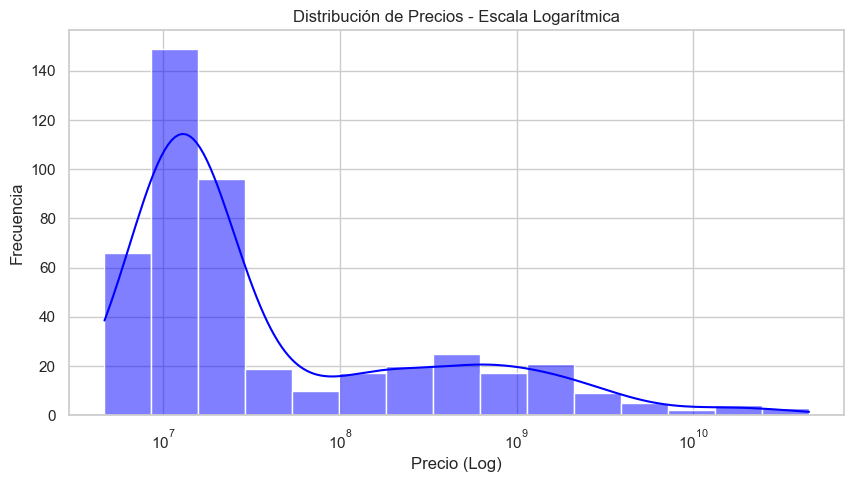

In [18]:
sns.set_theme(style="whitegrid")


plt.figure(figsize=(10, 5))
sns.histplot(df['Precio'], kde=True, color='blue', log_scale=True)

plt.title('Distribución de Precios - Escala Logarítmica')
plt.xlabel('Precio (Log)')
plt.ylabel('Frecuencia')
plt.show()

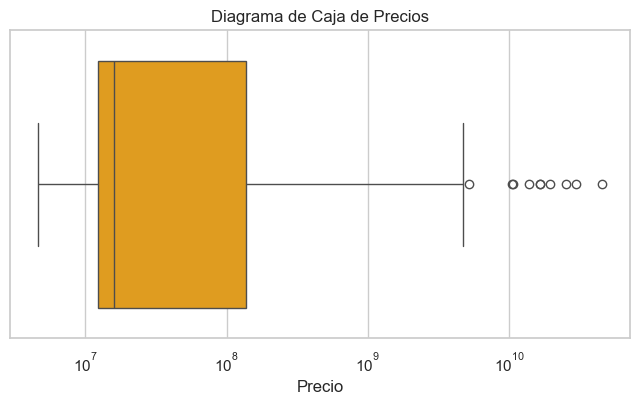

In [19]:
plt.figure(figsize=(8, 4))
sns.boxplot(x=df['Precio'], color='orange', log_scale=True)
plt.title('Diagrama de Caja de Precios')
plt.xlabel('Precio')
plt.show()

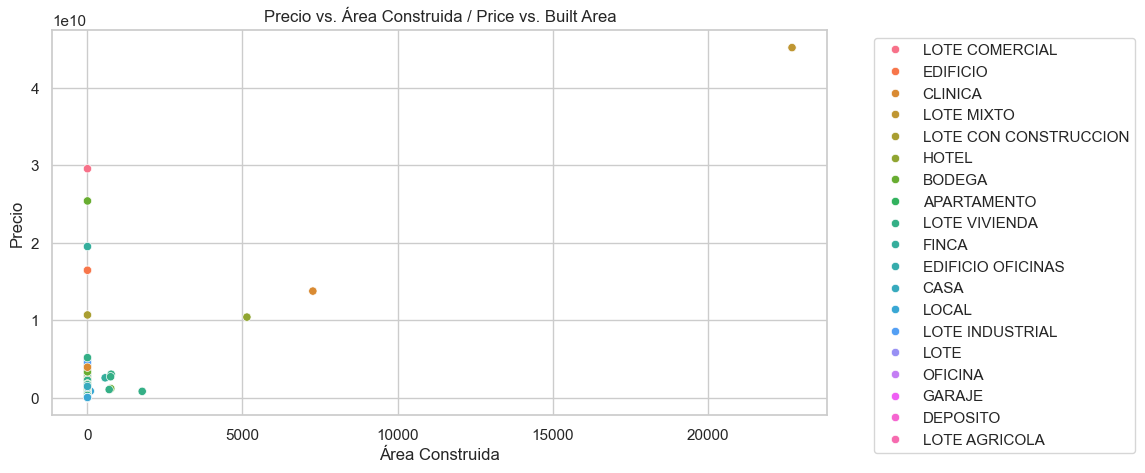

In [20]:
plt.figure(figsize=(10, 5))
sns.scatterplot(data=df, x='Area Construida', y='Precio', hue='Tipo de Inmueble')
plt.title('Precio vs. Área Construida / Price vs. Built Area')
plt.xlabel('Área Construida')
plt.ylabel('Precio')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.show()

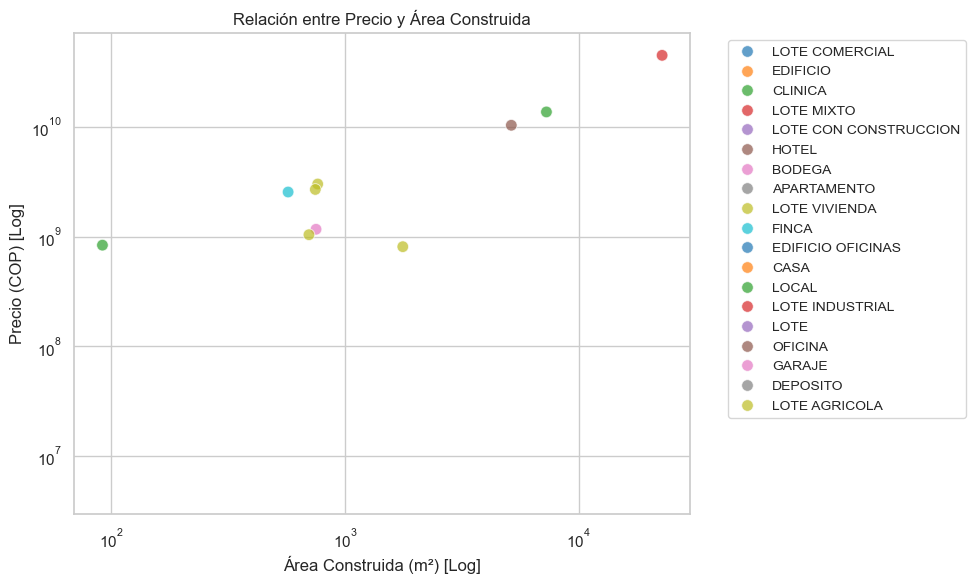

In [21]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='Area Construida',
    y='Precio',
    hue='Tipo de Inmueble',
    palette='tab10',
    alpha=0.7,
    s=70
)

plt.yscale('log')
plt.xscale('log')
plt.title('Relación entre Precio y Área Construida')
plt.xlabel('Área Construida (m²) [Log]')
plt.ylabel('Precio (COP) [Log]')
plt.legend(
    bbox_to_anchor=(1.05, 1),
    loc='upper left',
    fontsize='small'
    )

plt.tight_layout()
plt.show()
plt.show()

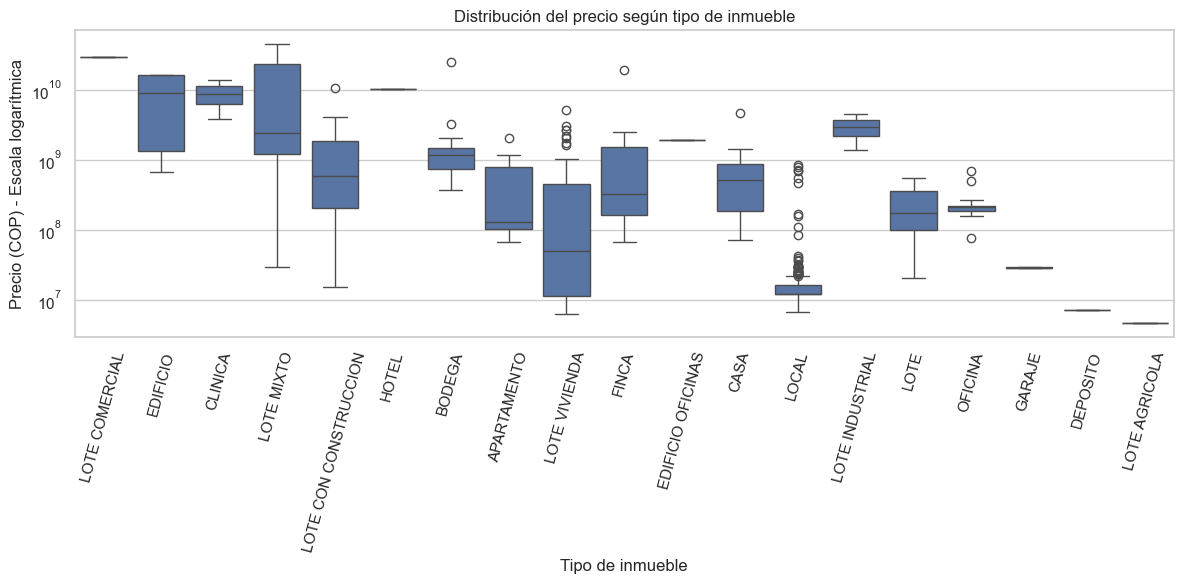

In [22]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df[df['Precio'] > 0],
    x='Tipo de Inmueble',
    y='Precio'
)

plt.yscale('log')
plt.title('Distribución del precio según tipo de inmueble')
plt.xlabel('Tipo de inmueble')
plt.ylabel('Precio (COP) - Escala logarítmica')
plt.xticks(rotation=75)
plt.tight_layout()
plt.show()

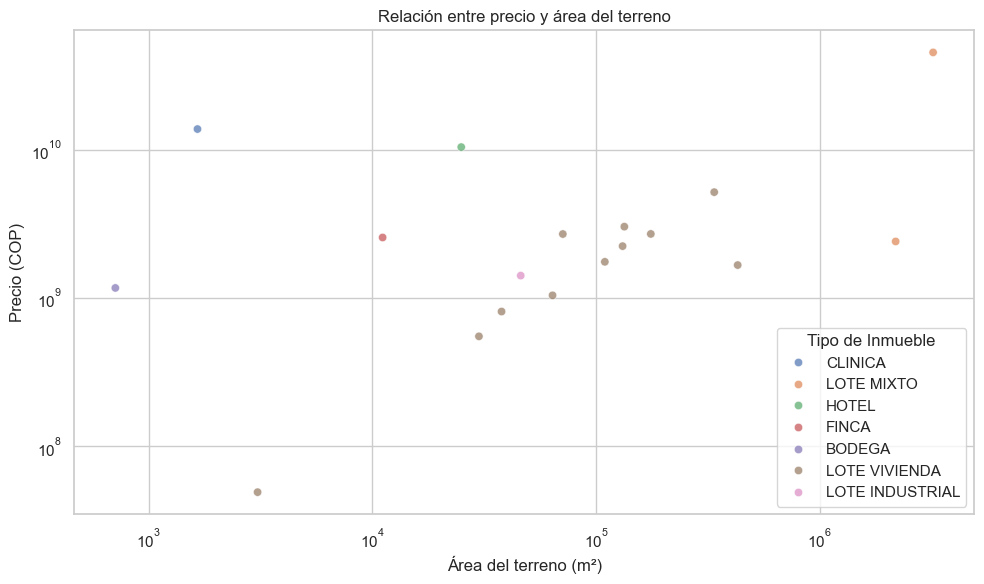

In [23]:
df_terreno = df[
    (df['Area Terreno'] > 0) &
    (df['Precio'] > 0)
]

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df_terreno,
    x='Area Terreno',
    y='Precio',
    hue='Tipo de Inmueble',
    alpha=0.7
)

plt.xscale('log')
plt.yscale('log')

plt.title('Relación entre precio y área del terreno')
plt.xlabel('Área del terreno (m²)')
plt.ylabel('Precio (COP)')
plt.tight_layout()
plt.show()

---
---
# Conclusión
---
El análisis exploratorio realizado permitió caracterizar el comportamiento del mercado inmobiliario registrado a partir de 463 inmuebles y 12 variables.

La mayoría de los inmuebles se ubica en rangos de precio bajos o medios, pero existen propiedades con valores muy altos que incrementan considerablemente la media.

La relación entre el área construida y el precio es positiva: en general, los inmuebles con mayor área construida tienden a presentar precios más altos.

Por lo anterior, se evidencia la necesidad de considerar las características físicas y categóricas de los inmuebles durante el análisis de sus precios. La transformación de unidades facilita la interpretación de los resultados, permite comparar mejor los inmuebles y evidencia que el mercado inmobiliario analizado es muy heterogéneo.

---
---

---
---
# Referencias
---
- Hunter, J. D. (2007). Matplotlib: A 2D graphics environment. Computing in Science & Engineering, 9(3), 90–95. https://doi.org/10.1109/MCSE.2007.55

- NumPy Developers. (2020). NumPy documentation. https://numpy.org/doc/

- pandas development team. (2010). pandas documentation. https://pandas.pydata.org/docs/

- Seaborn development team. (2021). seaborn: Statistical data visualization. https://seaborn.pydata.org/



---
---